## 01 — Setup and Shared Storage

In [1]:
from pathlib import Path
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
SEED = 42
# Optional shared storage: mount Drive for persistent files across Colab notebooks.
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = Path('/content/drive/MyDrive/CAI470_Project')
else:
    ROOT = Path.cwd() / 'CAI470_Project'
RAW = ROOT / 'raw'
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
for p in [RAW, OUT, FIG]: p.mkdir(parents=True, exist_ok=True)
print('Shared project folder:', ROOT)

Mounted at /content/drive
Shared project folder: /content/drive/MyDrive/CAI470_Project


## 02 — Load Original Train and Test

In [2]:
TRAIN_NAME = 'UNSW_NB15_training-set.csv'
TEST_NAME = 'UNSW_NB15_testing-set.csv'
BASE_URL = 'https://raw.githubusercontent.com/jamshaid120/UNSW_NB15-Complete-dataset/main/'
# Mirror of the official fixed UNSW-NB15 train/test partition.
# If downloading is blocked, upload the two ORIGINAL CSV files from UNSW here.
for name in [TRAIN_NAME, TEST_NAME]:
    path = RAW / name
    if not path.is_file():
        try:
            print('Downloading:', name)
            import requests
            response = requests.get(BASE_URL + name, timeout=120)
            response.raise_for_status()
            path.write_bytes(response.content)
        except Exception as e:
            print('Automatic download unavailable:', type(e).__name__)
            if 'google.colab' in sys.modules:
                from google.colab import files as colab_files
                print('Upload ORIGINAL:', name)
                uploaded = colab_files.upload()
                match = next((v for k,v in uploaded.items() if Path(k).name.lower()==name.lower()), None)
                if match is None:
                    raise FileNotFoundError(f'Please upload {name}; provided files: {list(uploaded)}')
                path.write_bytes(match)
            else:
                raise FileNotFoundError(f'Download or place {name} into {RAW}') from e
    if path.stat().st_size < 1_000_000:
        raise ValueError(f'{name} is unexpectedly small; check the source CSV.')
train = pd.read_csv(RAW/TRAIN_NAME, low_memory=False)
test = pd.read_csv(RAW/TEST_NAME, low_memory=False)
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()
assert len(train) == 175341 and len(test) == 82332, (train.shape, test.shape)
assert list(train.columns) == list(test.columns), 'Train/test columns do not match.'
assert {'id','attack_cat','label'}.issubset(train.columns)
assert set(pd.to_numeric(train.label).unique()) <= {0,1}
assert set(pd.to_numeric(test.label).unique()) <= {0,1}
print('Training:', train.shape, 'Testing:', test.shape)

Training: (175341, 45) Testing: (82332, 45)


## 03 — Define Features and Labels

In [3]:
TARGET = 'label'
EXCLUDE = ['id', 'attack_cat', TARGET]
FEATURES = [c for c in train.columns if c not in EXCLUDE]
CAT = [c for c in ['proto', 'service', 'state'] if c in FEATURES]
NUM = [c for c in FEATURES if c not in CAT]
assert len(FEATURES) == 42, f'Expected 42 features, found {len(FEATURES)}'
for df in (train,test):
    for col in CAT:
        df[col] = df[col].fillna('Unknown').astype(str).str.strip()
    for col in NUM:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].replace([np.inf,-np.inf], np.nan)
y_train = train[TARGET].astype(int)
y_test = test[TARGET].astype(int)
X_train, X_test = train[FEATURES].copy(), test[FEATURES].copy()
assert not set(EXCLUDE).intersection(X_train.columns)
assert list(X_train.columns) == list(X_test.columns)
print('Features:',len(FEATURES),'Numerical:',len(NUM),'Categorical:',CAT)

Features: 42 Numerical: 39 Categorical: ['proto', 'service', 'state']


## 04 — Preprocessing Pipelines

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
# Sparse encoding: avoids creating a very large dense design matrix.
num_scaled=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
cat_onehot=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))])
pre_scaled=ColumnTransformer([('num',num_scaled,NUM),('cat',cat_onehot,CAT)],sparse_threshold=1.0)
pre_trees=ColumnTransformer([('num',SimpleImputer(strategy='median'),NUM),('cat',cat_onehot,CAT)],sparse_threshold=1.0)
# HistGradientBoosting requires dense numerical input; ordinal categories are marked as categorical.
cat_ordinal=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))])
pre_hgb=ColumnTransformer([('num',SimpleImputer(strategy='median'),NUM),('cat',cat_ordinal,CAT)],sparse_threshold=0.0)
print('Numeric:',len(NUM),'Categorical:',len(CAT))

Numeric: 39 Categorical: 3


## 05 — Initialize Four Classifiers

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
models = {
  'Logistic Regression': Pipeline([('preprocess',pre_scaled),('model',LogisticRegression(max_iter=500,solver='liblinear',class_weight='balanced',random_state=SEED))]),
  'Decision Tree': Pipeline([('preprocess',pre_trees),('model',DecisionTreeClassifier(max_depth=22,min_samples_leaf=5,random_state=SEED))]),
  'Random Forest': Pipeline([('preprocess',pre_trees),('model',RandomForestClassifier(n_estimators=100,max_depth=24,min_samples_leaf=2,n_jobs=-1,random_state=SEED))]),
  'HistGradientBoosting': Pipeline([('preprocess',pre_hgb),('model',HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=31,learning_rate=0.08,l2_regularization=1.0,categorical_features=list(range(len(NUM),len(NUM)+len(CAT))),random_state=SEED))])
}
print('Configured:',list(models))

Configured: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'HistGradientBoosting']


## 06 — Model Training

In [6]:
import time
fit_times={}
for name, model in models.items():
    start=time.perf_counter()
    print('Training',name,flush=True)
    model.fit(X_train,y_train)
    fit_times[name]=round(time.perf_counter()-start,2)
    print('Finished',name,'in',fit_times[name],'seconds',flush=True)
assert len(fit_times)==4

Training Logistic Regression
Finished Logistic Regression in 16.03 seconds
Training Decision Tree
Finished Decision Tree in 13.33 seconds
Training Random Forest
Finished Random Forest in 115.32 seconds
Training HistGradientBoosting
Finished HistGradientBoosting in 12.68 seconds


## 07 — Predictions and Metrics

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score
records=[]; pred_frame=pd.DataFrame({'id':test['id'].to_numpy(),'actual':y_test.to_numpy(),'attack_cat':test['attack_cat'].fillna('Normal').astype(str).to_numpy()})
for name, model in models.items():
    pred=model.predict(X_test)
    proba=model.predict_proba(X_test)[:,1]
    tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    records.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1-score':f1_score(y_test,pred,zero_division=0),'ROC-AUC':roc_auc_score(y_test,proba),'PR-AUC':average_precision_score(y_test,proba),'FP':int(fp),'FN':int(fn),'TP':int(tp),'TN':int(tn),'Fit seconds':fit_times[name]})
    tag=name.lower().replace(' ','_')
    pred_frame[f'{tag}_prediction']=pred
    pred_frame[f'{tag}_probability']=proba
results=pd.DataFrame(records).sort_values(['F1-score','Recall'],ascending=False)
display(results.round(4))
assert len(results)==4

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,FP,FN,TP,TN,Fit seconds
3,HistGradientBoosting,0.8729,0.8210,0.9835,0.8950,0.9855,0.9895,9719,747,44585,27281,12.68
2,Random Forest,0.8652,0.8086,0.9893,0.8899,0.9823,0.9868,10616,483,44849,26384,115.32
1,Decision Tree,0.8680,0.8269,0.9615,0.8891,0.9106,0.8806,9125,1746,43586,27875,13.33
0,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9560,0.9666,10400,3145,42187,26600,16.03


## 08 — Comparison Charts

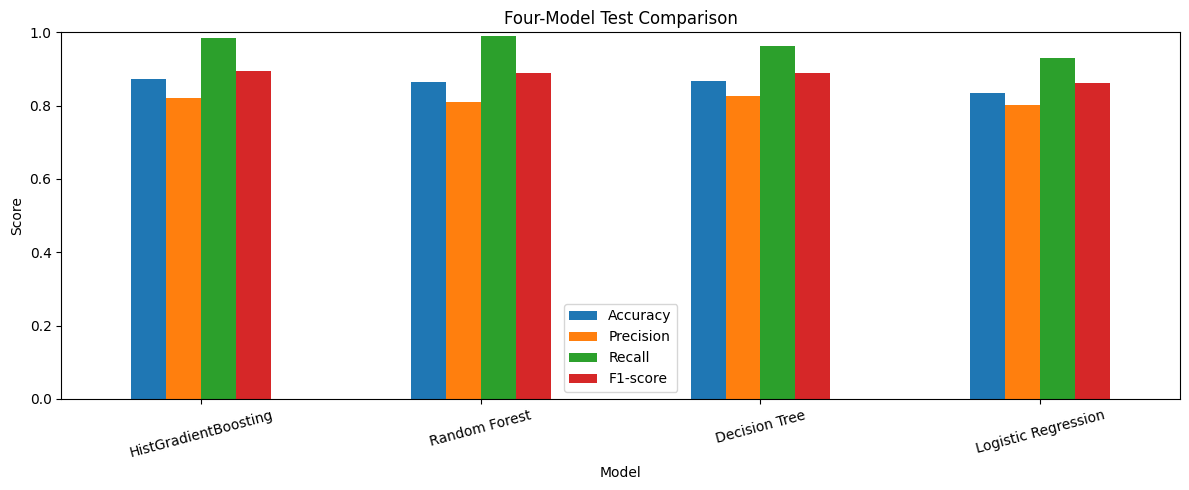

In [8]:
ax=results.set_index('Model')[['Accuracy','Precision','Recall','F1-score']].plot.bar(figsize=(12,5),ylim=(0,1),rot=15)
ax.set_title('Four-Model Test Comparison');ax.set_ylabel('Score');plt.tight_layout();plt.savefig(FIG/'four_model_comparison.png',dpi=150);plt.show()

## 09 — Four Confusion Matrices

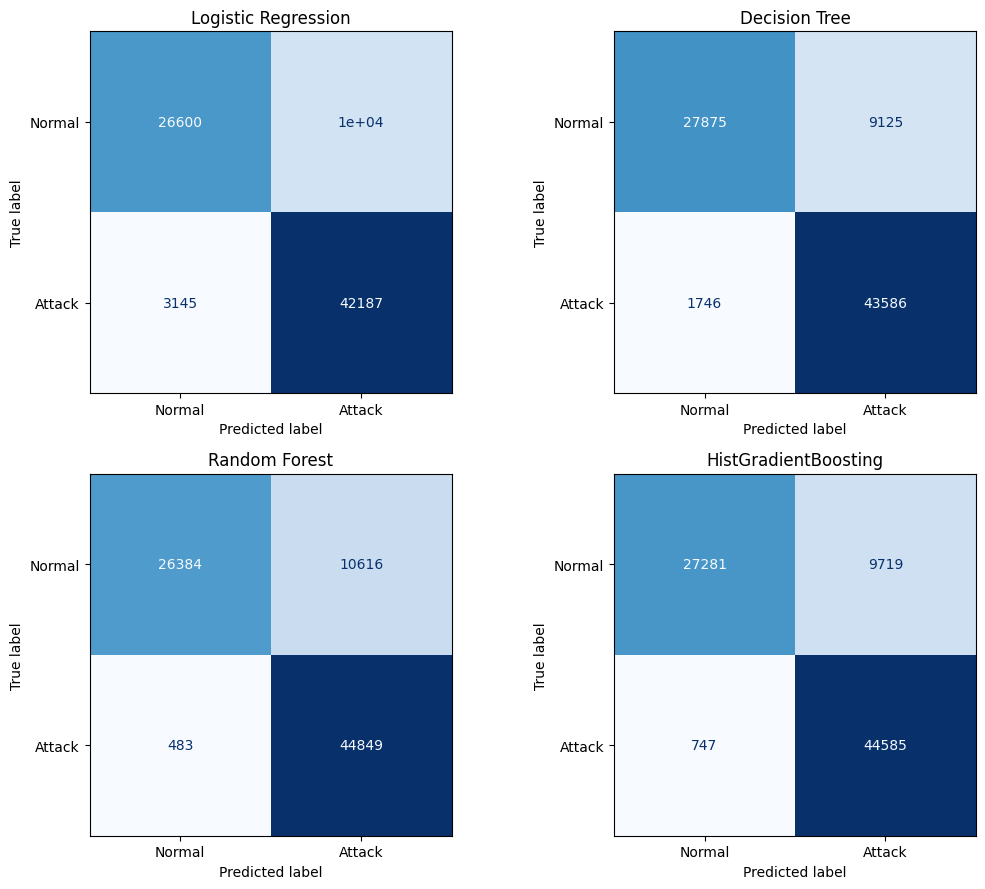

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
fig,axs=plt.subplots(2,2,figsize=(11,9))
for ax,(name,model) in zip(axs.flat,models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,model.predict(X_test),display_labels=['Normal','Attack'],cmap='Blues',colorbar=False,ax=ax)
    ax.set_title(name)
plt.tight_layout();plt.savefig(FIG/'confusion_matrices.png',dpi=150);plt.show()

## 10 — Choose Best Model

In [10]:
# Test comparison is descriptive; do not tune hyperparameters on the test set.
# F1 is the main metric, attack Recall breaks ties.
best_name=results.iloc[0]['Model'];best_model=models[best_name]
print('Best by held-out test F1 (recall tiebreak):',best_name)
print(results[['Model','Accuracy','Precision','Recall','F1-score','FP','FN']].round(4).to_string(index=False))

Best by held-out test F1 (recall tiebreak): HistGradientBoosting
               Model  Accuracy  Precision  Recall  F1-score    FP   FN
HistGradientBoosting    0.8729     0.8210  0.9835    0.8950  9719  747
       Random Forest    0.8652     0.8086  0.9893    0.8899 10616  483
       Decision Tree    0.8680     0.8269  0.9615    0.8891  9125 1746
 Logistic Regression    0.8355     0.8022  0.9306    0.8617 10400 3145


## 11 — Global Explainability

Permutation importance for: HistGradientBoosting on 1000 training samples


,Feature,Mean F1 decrease,Std
9,sttl,0.270229,0.005926
40,ct_srv_dst,0.014759,0.001362
26,smean,0.011938,0.001751
6,sbytes,0.011810,0.003441
2,service,0.011087,0.002670
1,proto,0.008551,0.000379
14,dloss,0.008498,0.000971
35,ct_dst_src_ltm,0.008318,0.000842
32,ct_dst_ltm,0.006740,0.000879
34,ct_dst_sport_ltm,0.006688,0.001194


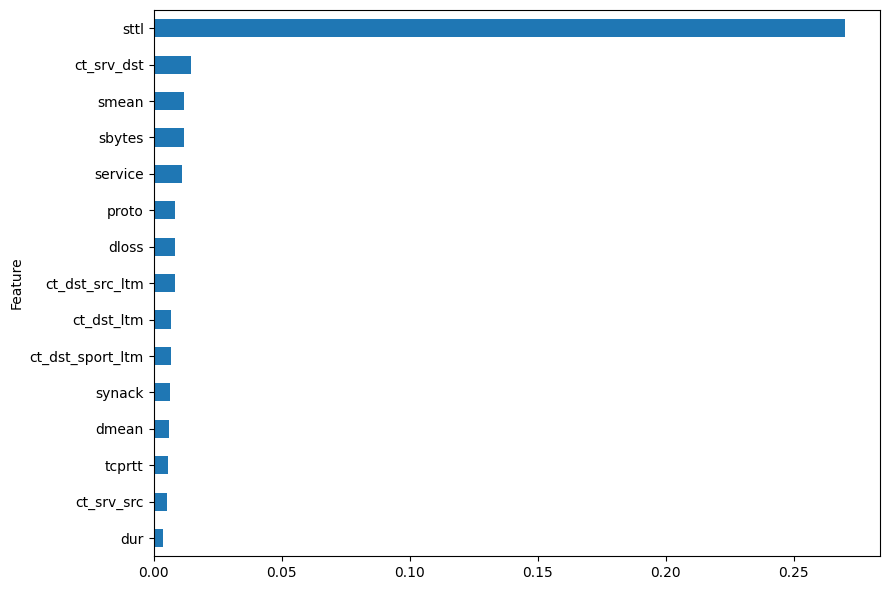

In [11]:
from sklearn.inspection import permutation_importance
# Explanations on a held-out TRAINING subset only, never used to modify the models.
from sklearn.model_selection import train_test_split
_,x_explain,_,y_explain=train_test_split(X_train,y_train,test_size=0.06,random_state=17,stratify=y_train)
x_explain=x_explain.iloc[:min(1000,len(x_explain))]
y_explain=y_explain.loc[x_explain.index]
print('Permutation importance for:',best_name,'on',len(x_explain),'training samples')
perm=permutation_importance(best_model,x_explain,y_explain,n_repeats=3,random_state=SEED,scoring='f1',n_jobs=1)
importance=pd.DataFrame({'Feature':FEATURES,'Mean F1 decrease':perm.importances_mean,'Std':perm.importances_std}).sort_values('Mean F1 decrease',ascending=False)
display(importance.head(15))
importance.to_csv(OUT/'best_model_permutation_importance.csv',index=False)
importance.head(15).sort_values('Mean F1 decrease').plot.barh(x='Feature',y='Mean F1 decrease',legend=False,figsize=(9,6));plt.tight_layout();plt.savefig(FIG/'feature_importance.png',dpi=150);plt.show()

## 12 — Save Reusable Results

In [12]:
results.to_csv(OUT/'model_comparison.csv',index=False)
pred_frame.to_csv(OUT/'test_predictions.csv',index=False)
(OUT/'best_model.json').write_text(json.dumps({'best_model':best_name,'selection_metric':'test F1, then test attack Recall','note':'No test-driven model tuning performed'},indent=2),encoding='utf-8')
print('Saved comparison, predictions, confusion matrix plots and feature importance to:',OUT)
print('No large .joblib model files required by Notebook 03.')

Saved comparison, predictions, confusion matrix plots and feature importance to: /content/drive/MyDrive/CAI470_Project/outputs
No large .joblib model files required by Notebook 03.
